# Git & GitHub: the fun way
**add = choose, commit = save, push = upload, pull = download**

## 1. What is Git?
**Git** = save points for your project, like in a video game. If you mess up, you go back to a save.
**GitHub** = the cloud where your saves live, so others can see them and help.

> **Fun fact:** Linus Torvalds, who created Linux, built Git in 2005 in about two weeks. The project had lost free access to the tool it used before, so he wrote a new one.

> **Fun fact:** "git" is British slang for an annoying person. Linus joked that he names all his projects after himself.

## 2. The 4 places your work lives

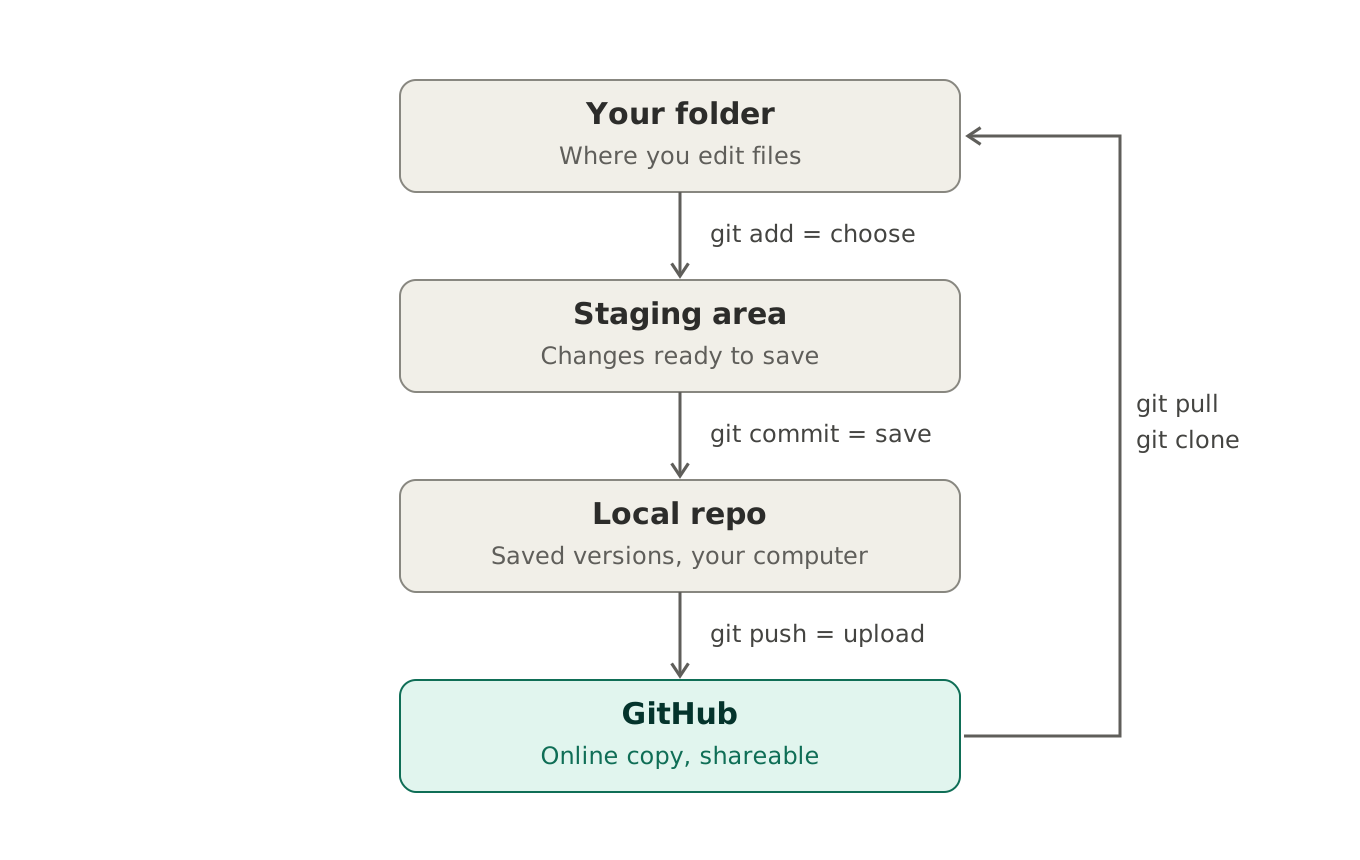

**Staging is like a group photo:** `git add` gets people into the frame, and `git commit` takes the picture.

> **Fun fact:** every commit gets a unique ID, a 40-character code like `a1b2c3d…`. You usually only need the first 7 characters to refer to it.

## 3. Branches: a "what if" world
A branch lets you try an idea without breaking `main`. When it works, you merge it back.

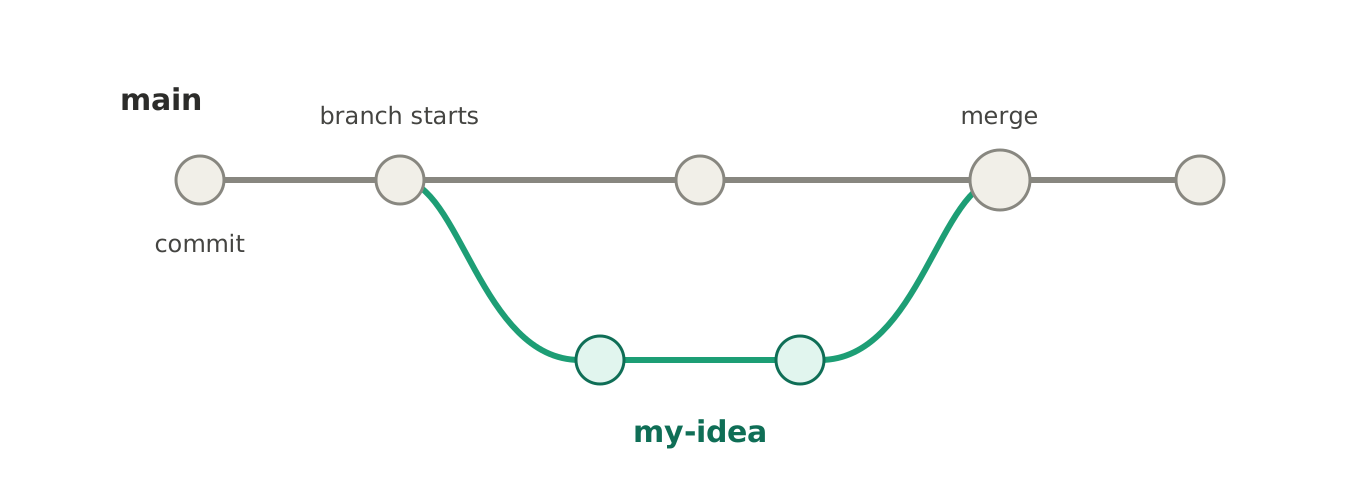

```bash
git checkout -b my-idea   # start the branch
git checkout main         # go back
git merge my-idea         # bring my-idea into main
```

**`main` vs `master`:** they work the same way. `master` is the old default name and `main` is the new one (GitHub switched in 2020). Run `git branch` to see which one a repo uses.

> **Fun fact:** if two branches change the same line, Git doesn't guess. It marks both versions with `<<<<<<<` and `>>>>>>>` and lets you choose. That's a **merge conflict**, and it's normal.

## 4. Helping on someone else's project

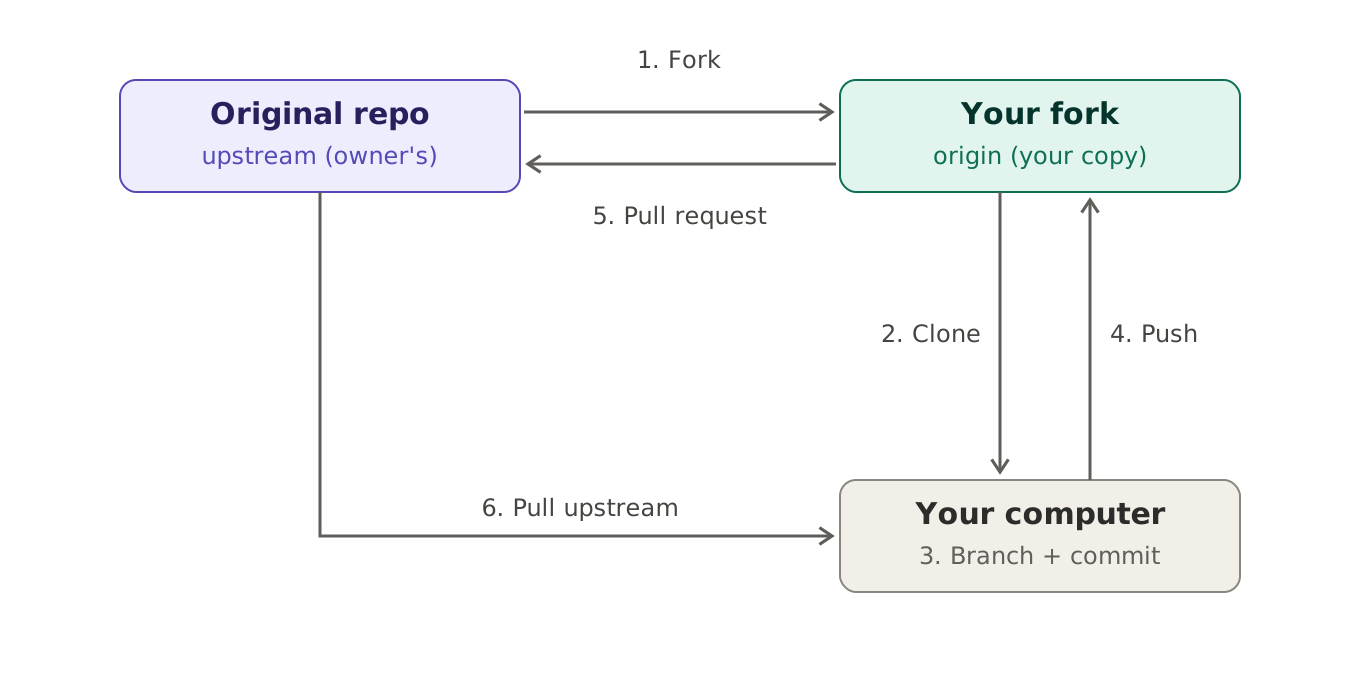

```bash
git clone git@github.com:YOU/repo.git      # 2. clone
git checkout -b my-fix                     # 3. branch
git add . && git commit -m "Fix typo"      # 3. commit
git push origin my-fix                     # 4. push
# 5. On GitHub: Compare & pull request → Create
git pull upstream main                     # 6. stay updated
```

**Watch out:** plain `git pull` only gets updates from **your fork**, not the original. Use `git pull upstream main`, or click **Sync fork** on GitHub.
Set up upstream once: `git remote add upstream git@github.com:OWNER/repo.git`

> **Fun fact:** GitHub's mascot is the **Octocat**, half cat and half octopus. GitHub started in 2008, and Microsoft bought it in 2018 for $7.5 billion.

> **Fun fact:** in 2020, GitHub stored a copy of public code inside a mountain in Svalbard, Norway (the Arctic Code Vault). It's built to last 1,000 years.

## 5. Setup (once)
```bash
git config --global user.name "Your Name"     # name tag, not a login
git config --global user.email "you@example.com"
git config --global init.defaultBranch main
```

**Connect with SSH.** Your computer keeps the private key, and GitHub gets the public one (`.pub`):
```bash
ssh-keygen -t ed25519 -C "you@example.com"   # press Enter at each question
cat ~/.ssh/id_ed25519.pub                    # copy, then paste in GitHub → Settings → SSH keys
ssh -T git@github.com                        # "Hi yourname!" = it worked
```
> **Fun fact:** GitHub stopped accepting account passwords in Git commands in 2021. That's why you need SSH or a token.

## 6. Cheat sheet
```bash
git init | git clone <url>          # start
git status                          # what changed?
git add .                           # choose
git commit -m "msg"                 # save
git push | git pull                 # upload | download
git log --oneline | git diff        # history | changes
git checkout -b name                # new branch
git merge name | git branch -d name # combine | delete
git restore file                    # discard changes
git revert <id>                     # safe undo after a push
```

## 7. Golden rules
1. Commit small and often, with clear messages.
2. Run `git pull` before you start working.
3. Use one branch per idea, and don't work directly on `main`.
4. If you already pushed, undo with `revert`, not `reset`.
5. Never commit passwords. Put them in `.gitignore`.

> **Fun fact:** the first description of Git in its own code called it "the stupid content tracker." 

## 8. Fixing a merge conflict, step by step
A conflict happens when two branches changed **the same lines**. Git stops and marks the file:
```
<<<<<<< HEAD
your version
=======
their version
>>>>>>> my-idea
```
**To fix it:**
1. Run `git status` to see which files have conflicts.
2. Open each file and keep the version you want (or mix both).
3. Delete the `<<<<<<<`, `=======` and `>>>>>>>` lines.
4. Save the file, then:
```bash
git add file.py
git commit -m "Fix merge conflict"
```
**Changed your mind?** `git merge --abort` puts everything back the way it was.

> **Tip:** VS Code shows buttons above each conflict: *Accept Current*, *Accept Incoming*, *Accept Both*.

## 9. Undoing things
| Problem | Fix |
|---|---|
| Throw away changes in a file (not staged) | `git restore file` |
| Unstage a file (keep the changes) | `git restore --staged file` |
| Fix the last commit message | `git commit --amend -m "new message"` |
| Forgot a file in the last commit | `git add file` then `git commit --amend --no-edit` |
| Undo the last commit, keep the changes | `git reset --soft HEAD~1` |
| Undo a commit that was already pushed (safe) | `git revert <commit-id>` |

**Rule:** if you already pushed, use `revert`. Only use `amend` or `reset` on commits that haven't been pushed.

### ⚠️ Danger zone: these can delete work
| Command | What it does |
|---|---|
| `git reset --hard` | Deletes all uncommitted changes. Gone. |
| `git push --force` | Overwrites GitHub's history, and can erase teammates' work |
| `git clean -fd` | Deletes all untracked files |

If AI (or anyone) suggests one of these, **stop and ask why** first. Make a backup copy of the folder if you're unsure.

## 10. `.gitignore`: files Git should skip
Create a file named `.gitignore` in the main project folder. Example for data science:
```
# secrets
.env
*.key

# Python
__pycache__/
*.pyc
.venv/

# Jupyter
.ipynb_checkpoints/

# data and outputs
data/raw/
*.csv
*.parquet
models/

# system files
.DS_Store
Thumbs.db
```
**Already committed a file by mistake?** Stop tracking it (the file stays on your computer):
```bash
git rm --cached file.csv        # one file
git rm -r --cached data/        # a folder
git commit -m "Stop tracking data"
```
> ⚠️ **If you pushed a password or API key, change the key right away.** Deleting the file doesn't remove it from the history.

> **Tip:** github.com/github/gitignore has ready-made templates for Python, R, Node and more.

## 11. Remotes and `fetch`
```bash
git remote -v                   # list remotes and their links
git remote add upstream <url>   # add the original project
git remote set-url origin <url> # change a link
git remote remove upstream      # remove one
```
| Command | What it does |
|---|---|
| `git fetch` | **Downloads** news only. Your files don't change |
| `git pull` | Downloads **and merges** (`fetch` + `merge`) |

Use `fetch` when you want to look before you apply: `git fetch`, then `git log --oneline main..origin/main` to see what's new.

## 12. Common errors and fixes
| Error | What it means | Fix |
|---|---|---|
| `rejected … fetch first` | GitHub has changes you don't have | `git pull`, then `git push` |
| `Permission denied (publickey)` | SSH isn't set up | Redo the SSH steps in section 5 |
| `not a git repository` | Wrong folder | `cd` into the project, or `git init` |
| `src refspec main does not match` | No commits yet, or the branch is `master` | Commit first, or check `git branch` |
| `remote origin already exists` | Link already added | `git remote set-url origin <url>` |
| `Your local changes would be overwritten` | Uncommitted work is in the way | Commit or `git stash`, then try again |
| `CONFLICT (content)` | Merge conflict | See section 8 |
| `File … exceeds 100 MB` | File too big for GitHub | See section 14 |

> **Tip:** paste the full error **and** the output of `git status` when you ask AI for help.

## 13. README.md: your project's front page
GitHub shows `README.md` on the repo's main page. It's written in **Markdown**, the same format as these notebook text cells.
```markdown
# Project name
One sentence on what it does.

## How to run
pip install -r requirements.txt
python main.py

## Data
Where the data comes from.

## Author
Your name
```
> **Fun fact:** if you make a repo with the **same name as your GitHub username**, its README shows up on your GitHub profile page.

## 14. Data science: big files and notebooks
**Big files**
- GitHub **blocks files over 100 MB** and warns above 50 MB.
- Keep data out of Git: put it in `.gitignore` and share it through Drive, S3, Kaggle and so on, or a download script.
- If you really need big files in Git, use **Git LFS**:
```bash
git lfs install
git lfs track "*.csv"
git add .gitattributes
```

**Notebooks (`.ipynb`)**
- Notebooks store outputs and run counts, so they change every time you run them and cause messy conflicts.
- **Clear outputs before committing:** *Kernel → Restart & Clear Output*.
- Or let a tool do it automatically:
```bash
pip install nbstripout
nbstripout --install     # strips outputs on every commit
```
- To compare notebooks readably: `pip install nbdime`, then `nbdiff a.ipynb b.ipynb`.
- Teamwork tip: **one person per notebook**, and move shared code into `.py` files.

## 15. Extras: good to know (ask AI when needed)
**Stash: put work aside**
```bash
git stash          # hide unfinished changes
git stash list     # see them
git stash pop      # bring them back
```
**`switch`: the newer way to change branch**
```bash
git switch main
git switch -c new-branch   # create + switch
```
**Tags: mark versions**
```bash
git tag v1.0
git push origin v1.0
```
**Rebase and cherry-pick**
- `git rebase main`: replays your branch on top of the latest `main` for a straight history. ⚠️ Don't rebase commits you already pushed and shared.
- `git cherry-pick <id>`: copies one specific commit onto your branch.

**GitHub features**
- **Issues**: a to-do and bug list for the project. Write `Fixes #12` in a PR to close issue 12 automatically.
- **PR reviews**: reviewers can *Comment*, *Approve* or *Request changes*. Push more commits to the same branch and the PR updates itself.
- **GitHub Pages**: free website hosting from a repo.
- **GitHub Actions**: automation, like running tests on every push.

**Without the terminal**
- **VS Code**: Source Control tab (the branch icon) for add, commit, push and conflicts.
- **GitHub Desktop**: a simple app for all the basics.

> **Fun fact:** `git bisect` finds which commit introduced a bug by testing halfway points, like a guessing game. It can search 1,000 commits in about 10 steps.

## 16. Quick quiz
1. Which command chooses changes?
2. Which one saves?
3. `origin` or `upstream`: which one is the original project?
4. Are `main` and `master` different?
5. What's the safe way to undo a commit you already pushed?
6. What's the difference between `fetch` and `pull`?
7. You pushed an API key by mistake. What must you do?
8. What's the largest file GitHub accepts?

<details><summary><b>Show answers</b></summary>

1. `git add`
2. `git commit`
3. `upstream`
4. No, only the name is different.
5. `git revert <id>`
6. `fetch` only downloads; `pull` downloads and merges.
7. Change (replace) the key. Deleting the file isn't enough.
8. 100 MB (use Git LFS or keep data out of Git).
</details>

## 17. Try it: check that Git is installed

In [ ]:
!git --version

---
**Fork (copy) → branch (try) → add (choose) → commit (save) → push (upload) → pull request (ask) → pull upstream (stay updated)**

Practice: [learngitbranching.js.org](https://learngitbranching.js.org/), a free game that teaches branches visually.